In [13]:
import pandas as pd

df = pd.read_csv("ab_data.csv")
print(df.shape)
df.head()

(294478, 5)


,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


In [14]:
pd.crosstab(df["group"], df["landing_page"])

landing_page,new_page,old_page
group,,
control,1928,145274
treatment,145311,1965


In [15]:
mismatch = ((df["group"] == "control") & (df["landing_page"] == "new_page")) | \
           ((df["group"] == "treatment") & (df["landing_page"] == "old_page"))
print("Galat rows:", mismatch.sum())

df = df[~mismatch]
print(len(df))

Galat rows: 3893
290585


In [16]:
print("Duplicate users:", df["user_id"].duplicated().sum())
df = df.drop_duplicates(subset="user_id", keep="first")
print(len(df))

Duplicate users: 1
290584


In [17]:
df["timestamp"] = pd.to_datetime(df["timestamp"])

In [18]:
print(df.shape)
print(df["group"].value_counts())
df.groupby("group")["converted"].agg(["sum", "count", "mean"]).round(4)

(290584, 5)
group
treatment    145310
control      145274
Name: count, dtype: int64


,sum,count,mean
group,,,
control,17489,145274,0.1204
treatment,17264,145310,0.1188


In [19]:
df.to_csv("AB_Clean.csv", index=False)

In [20]:
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

control = df[df["group"] == "control"]["converted"]
treatment = df[df["group"] == "treatment"]["converted"]

print("Control rate:", round(control.mean() * 100, 2), "%")
print("Treatment rate:", round(treatment.mean() * 100, 2), "%")
print("Fark:", round((treatment.mean() - control.mean()) * 100, 2), "percentage points")

Control rate: 12.04 %
Treatment rate: 11.88 %
Fark: -0.16 percentage points


In [21]:
z_stat, p_value = proportions_ztest(
    [treatment.sum(), control.sum()],
    [len(treatment), len(control)]
)
print("Z-score:", round(z_stat, 3))
print("p-value:", round(p_value, 3))

Z-score: -1.311
p-value: 0.19


In [22]:
low, high = confint_proportions_2indep(
    treatment.sum(), len(treatment),
    control.sum(), len(control),
    compare="diff", method="wald"
)
print("95% interval:", round(low * 100, 2), "se", round(high * 100, 2), "percentage points")

95% interval: -0.39 se 0.08 percentage points


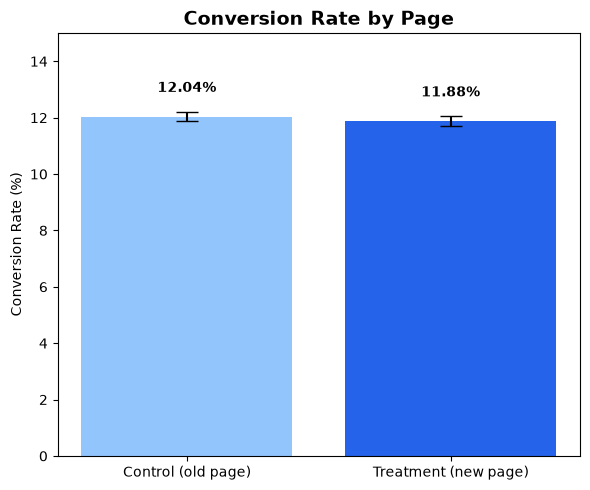

In [23]:
import matplotlib.pyplot as plt
import numpy as np

rates = df.groupby("group")["converted"].agg(["mean", "count"])
rates["rate"] = rates["mean"] * 100
rates["error"] = 1.96 * np.sqrt(rates["mean"] * (1 - rates["mean"]) / rates["count"]) * 100
rates = rates.loc[["control", "treatment"]]

plt.figure(figsize=(6, 5))
bars = plt.bar(["Control (old page)", "Treatment (new page)"], rates["rate"],
               yerr=rates["error"], capsize=8, color=["#93C5FD", "#2563EB"])
plt.bar_label(bars, labels=[f"{v:.2f}%" for v in rates["rate"]], padding=12, fontweight="bold")
plt.title("Conversion Rate by Page", fontsize=14, fontweight="bold")
plt.ylabel("Conversion Rate (%)")
plt.ylim(0, 15)
plt.tight_layout()
plt.savefig("chart1_conversion.png", dpi=150)
plt.show()

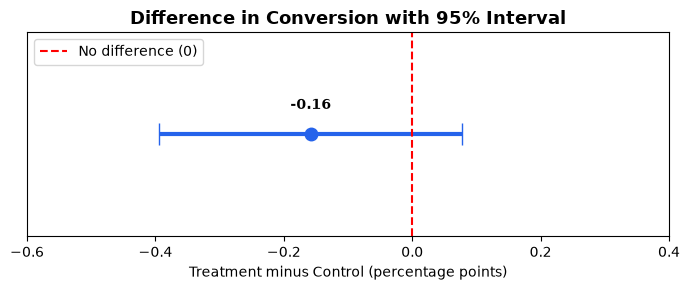

In [24]:
from statsmodels.stats.proportion import confint_proportions_2indep

low, high = confint_proportions_2indep(
    treatment.sum(), len(treatment), control.sum(), len(control),
    compare="diff", method="wald")
diff = (treatment.mean() - control.mean()) * 100
low, high = low * 100, high * 100

plt.figure(figsize=(7, 3))
plt.errorbar(diff, 0, xerr=[[diff - low], [high - diff]], fmt="o", color="#2563EB",
             capsize=8, markersize=9, linewidth=3)
plt.axvline(0, color="red", linestyle="--", label="No difference (0)")
plt.xlim(-0.6, 0.4)
plt.ylim(-1, 1)
plt.yticks([])
plt.xlabel("Treatment minus Control (percentage points)")
plt.title("Difference in Conversion with 95% Interval", fontsize=13, fontweight="bold")
plt.text(diff, 0.25, f"{diff:.2f}", ha="center", fontweight="bold")
plt.legend(loc="upper left")
plt.tight_layout()
plt.savefig("chart2_difference.png", dpi=150)
plt.show()